# Đáp án mã · Bài 4 — Mô hình ngôn ngữ n-gram

Giải **các bài tập của Bài 4** bằng mã chạy được. Hãy tự làm trước, rồi đối chiếu. Ô đầu dựng lại mô hình của Bài 4 (mã y hệt).

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

ROOT = pathlib.Path.cwd()
while not (ROOT / "nlpvi").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import math, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nlpvi import load_splits, normalize, segment, split_sentences, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
train, valid, test = load_splits()

def cau_thanh_tu(text):
    out = []
    for cau in split_sentences(normalize(text, emoji="drop", expand_teencode=True)):
        toks = [w for w in segment(cau).split() if any(ch.isalnum() for ch in w)]
        if toks:
            out.append(toks)
    return out

S_tr_raw = [s for t in train["text"] for s in cau_thanh_tu(t)]
dem_tu = Counter(w for s in S_tr_raw for w in s)
TU_DIEN = {w for w, c in dem_tu.items() if c >= 2} | {"<unk>"}
thay_unk = lambda sents: [[w if w in TU_DIEN else "<unk>" for w in s] for s in sents]
S_tr = thay_unk(S_tr_raw)
S_va = thay_unk([s for t in valid["text"] for s in cau_thanh_tu(t)])
S_te = thay_unk([s for t in test["text"] for s in cau_thanh_tu(t)])

def dem_ngram(sents, n):
    c = Counter()
    for s in sents:
        toks = ["<s>"] * (n - 1) + s + ["</s>"]
        for i in range(len(toks) - n + 1):
            c[tuple(toks[i:i + n])] += 1
    return c

class MoHinhNgram:
    """Trigram nội suy (đúng như Bài 4)."""
    def __init__(self, C1, C2, C3, V, lam=(0.1, 0.4, 0.5), k_uni=0.1):
        self.C1, self.C2, self.C3, self.V, self.lam, self.k = C1, C2, C3, V, lam, k_uni
        self.tong_uni = sum(C1.values())
        self.ctx2, self.ctx3 = Counter(), Counter()
        for (a, b), c in C2.items(): self.ctx2[(a,)] += c
        for (a, b, c_), c in C3.items(): self.ctx3[(a, b)] += c
    def p_uni(self, w): return (self.C1[(w,)] + self.k) / (self.tong_uni + self.k * self.V)
    def p_bi(self, v, w):
        n = self.ctx2[(v,)]; return self.C2[(v, w)] / n if n else 0.0
    def p_tri(self, u, v, w):
        n = self.ctx3[(u, v)]; return self.C3[(u, v, w)] / n if n else 0.0
    def p(self, u, v, w):
        l1, l2, l3 = self.lam
        return l1 * self.p_uni(w) + l2 * self.p_bi(v, w) + l3 * self.p_tri(u, v, w)
    def logp_cau(self, s):
        t = ["<s>", "<s>"] + s + ["</s>"]
        return sum(math.log(self.p(t[i - 2], t[i - 1], t[i])) for i in range(2, len(t)))

def perplexity(model, sents):
    return math.exp(-sum(model.logp_cau(s) for s in sents) / sum(len(s) + 1 for s in sents))

C1, C2, C3 = dem_ngram(S_tr, 1), dem_ngram(S_tr, 2), dem_ngram(S_tr, 3)
V = len(C1)
print("V =", V, "| số câu train/valid/test:", len(S_tr), len(S_va), len(S_te))

V = 458 | số câu train/valid/test: 2254 512 480


## Bài tập 1 — Perplexity trên test của mô hình đã chọn

In [2]:
LAM = (0.1, 0.3, 0.6)           # kết quả tìm lưới trên valid ở Bài 4
m = MoHinhNgram(C1, C2, C3, V, lam=LAM)
pd.DataFrame({"perplexity": {"train": perplexity(m, S_tr), "valid": perplexity(m, S_va), "test": perplexity(m, S_te)}}).round(2)

,perplexity
train,4.47
valid,8.73
test,9.28


**Đọc kết quả.** Perplexity **test** (≈9,2) gần với **valid** (≈8,7); test hơi cao hơn vì λ đã chọn trên valid nên valid hơi "quen". Perplexity **train** (≈4,7) thấp hơn nhiều — mô hình "nhớ" train. Quy tắc: báo cáo test *một lần*, sau khi đã chốt mọi lựa chọn bằng valid.

## Bài tập 2 — Ảnh hưởng của `k_uni`

In [3]:
rows = []
for k in [0.001, 0.01, 0.1, 1.0]:
    mm = MoHinhNgram(C1, C2, C3, V, lam=LAM, k_uni=k)
    rows.append({"k_uni": k, "PP valid": round(perplexity(mm, S_va), 2)})
pd.DataFrame(rows).set_index("k_uni")

,PP valid
k_uni,
0.001,8.73
0.010,8.73
0.100,8.73
1.000,8.70


**Đọc kết quả.** PP valid gần như **không đổi** (≈8,75 → ≈8,72) khi `k_uni` đi từ 0,001 đến 1. Lý do: `k_uni` chỉ ảnh hưởng tới xác suất unigram của từ hiếm và `<unk>`, mà unigram chỉ chiếm λ₁ = 0,1 trong nội suy. (Con số tốt nhất ở k = 1 chỉ hơn 0,03 — khác biệt vô nghĩa, đừng đọc thành "Laplace tốt hơn".) Đây là ví dụ một siêu tham số **ít nhạy** — đừng tốn thời gian tinh chỉnh nó. Hãy so với bài tập 3, nơi `k` *rất* nhạy vì nó chi phối cả mô hình bigram.

## Bài tập 3 — Add-k cho bigram, vẽ PP theo `k`

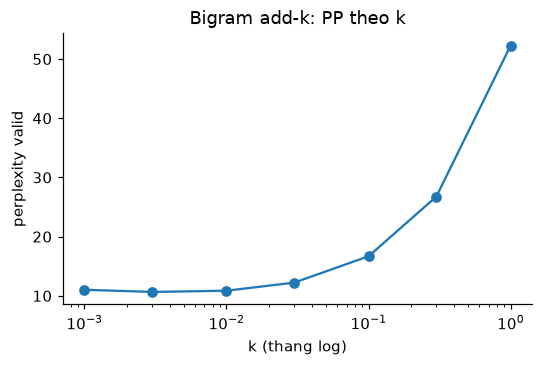

{0.001: 11.0, 0.003: 10.7, 0.01: 10.9, 0.03: 12.2, 0.1: 16.7, 0.3: 26.8, 1.0: 52.3} → tốt nhất tại k = 0.003


In [4]:
class BigramAddK:
    def __init__(self, C1, C2, V, k):
        self.C2, self.k, self.V = C2, k, V
        self.ctx = Counter()
        for (a, b), c in C2.items(): self.ctx[a] += c
    def p(self, v, w):
        return (self.C2[(v, w)] + self.k) / (self.ctx[v] + self.k * self.V)
    def logp_cau(self, s):
        t = ["<s>"] + s + ["</s>"]
        return sum(math.log(self.p(t[i - 1], t[i])) for i in range(1, len(t)))

ks = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
pp = [perplexity(BigramAddK(C1, C2, V, k), S_va) for k in ks]
plt.figure(figsize=(5.5, 3.2)); plt.semilogx(ks, pp, marker="o")
plt.xlabel("k (thang log)"); plt.ylabel("perplexity valid"); plt.title("Bigram add-k: PP theo k"); plt.show()
print({k: round(float(v), 1) for k, v in zip(ks, pp)}, "→ tốt nhất tại k =", ks[int(np.argmin(pp))])

**Đọc kết quả.** Đường cong có dạng **chữ U**: k quá nhỏ → các cặp chưa thấy bị gán xác suất ≈0 (phạt nặng khi gặp ở valid); k quá lớn → phân bố bị "làm phẳng" quá mức, mất thông tin. Ở đây tối ưu tại **k ≈ 0,003–0,01** (PP ≈10,7–10,9); với k = 1 (Laplace) PP vọt lên ≈52 — gấp khoảng 5 lần. Với bigram trên từ điển ~460 từ, Laplace "chia" quá nhiều xác suất cho các cặp chưa từng thấy; điểm tối ưu thường **rất nhỏ**, xa giá trị k = 1 mà sách giáo khoa hay nêu. Cũng để ý PP của bigram add-k tốt nhất (≈10,7) vẫn kém nội suy trigram (≈8,7).

## Bài tập 4 — Stupid backoff

Stupid backoff: nếu trigram có đếm > 0 dùng nó; nếu không, lùi về bigram nhân 0,4; không có nữa thì lùi về unigram nhân 0,4². **Không phải xác suất chuẩn hóa** (tổng ≠ 1) nên không tính được perplexity đúng nghĩa; ta so bằng **phép thử độ trôi chảy** của Bài 4 (câu thật so với câu xáo trộn).

In [5]:
class StupidBackoff:
    def __init__(self, base, alpha=0.4):
        self.b, self.a = base, alpha
    def s(self, u, v, w):
        b = self.b
        if b.ctx3[(u, v)] and b.C3[(u, v, w)]:
            return b.C3[(u, v, w)] / b.ctx3[(u, v)]
        if b.ctx2[(v,)] and b.C2[(v, w)]:
            return self.a * b.C2[(v, w)] / b.ctx2[(v,)]
        return self.a ** 2 * b.p_uni(w)
    def logp_cau(self, s):
        t = ["<s>", "<s>"] + s + ["</s>"]
        return sum(math.log(self.s(t[i - 2], t[i - 1], t[i])) for i in range(2, len(t)))

noi_suy = MoHinhNgram(C1, C2, C3, V, lam=LAM)
sb = StupidBackoff(noi_suy)
rng = random.Random(0)
cau = [s for s in S_va if 4 <= len(s) <= 12]
thang = {"nội suy": 0.0, "stupid backoff": 0.0}; n = 0
for s in cau:
    s2 = s[:]
    for _ in range(10):
        rng.shuffle(s2)
        if s2 != s: break
    if s2 == s: continue
    n += 1
    for ten, mo in [("nội suy", noi_suy), ("stupid backoff", sb)]:
        a, b = mo.logp_cau(s), mo.logp_cau(s2)
        thang[ten] += 0.5 if abs(a - b) < 1e-9 else float(a > b)
pd.DataFrame({"tỉ lệ xếp câu thật cao hơn câu xáo": {k: round(v / n, 3) for k, v in thang.items()}, "số cặp thử": n})

,tỉ lệ xếp câu thật cao hơn câu xáo,số cặp thử
nội suy,0.994,328
stupid backoff,0.994,328


**Đọc kết quả.** Hai cách cho kết quả gần như ngang nhau ở phép thử này. Ưu điểm của stupid backoff là **đơn giản và nhanh** (không cần tính trọng số, không chuẩn hóa) nên được dùng cho kho văn bản khổng lồ (Brants và cộng sự, 2007); nhược điểm là điểm số **không phải xác suất** nên không so được perplexity.

## Bài tập 5 (khó) — Bộ phân loại sinh: hai mô hình ngôn ngữ

Huấn luyện một mô hình ngôn ngữ cho mỗi lớp (*tích cực*, *tiêu cực*); phân loại một đánh giá mới bằng cách so xác suất của nó dưới hai mô hình, cộng log tiên nghiệm (quy tắc Bayes: $\hat c=\arg\max_c \log P(c)+\log P(\text{văn bản}\mid c)$). Ta chỉ xét hai lớp này (bỏ *trung tính*) để so với Logistic Regression ở Bài 3.

In [6]:
LOP = ["tích cực", "tiêu cực"]
tr2, va2 = train[train["label"].isin(LOP)], valid[valid["label"].isin(LOP)]

mo_hinh_lop, tien_nghiem = {}, {}
for lop in LOP:
    sents = thay_unk([s for t in tr2.loc[tr2["label"] == lop, "text"] for s in cau_thanh_tu(t)])
    mo_hinh_lop[lop] = MoHinhNgram(dem_ngram(sents, 1), dem_ngram(sents, 2), dem_ngram(sents, 3), V, lam=(0.2, 0.4, 0.4), k_uni=0.1)
    tien_nghiem[lop] = math.log((tr2["label"] == lop).mean())

def phan_loai(text):
    sents = thay_unk(cau_thanh_tu(text))
    diem = {lop: tien_nghiem[lop] + sum(mo_hinh_lop[lop].logp_cau(s) for s in sents) for lop in LOP}
    return max(diem, key=diem.get)

pred = [phan_loai(t) for t in va2["text"]]
acc_sinh = np.mean(np.array(pred) == va2["label"].values)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
tv = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
lr = LogisticRegression(C=10, max_iter=2000).fit(tv.fit_transform(tr2["text"].map(normalize)), tr2["label"])
acc_lr = np.mean(lr.predict(tv.transform(va2["text"].map(normalize))) == va2["label"].values)
print(f"Chỉ 2 lớp, {len(va2)} mẫu valid | bộ phân loại sinh (2 LM): {acc_sinh:.3f} | Logistic Regression: {acc_lr:.3f}")

Chỉ 2 lớp, 216 mẫu valid | bộ phân loại sinh (2 LM): 0.884 | Logistic Regression: 0.907


**Đọc kết quả.** Bộ phân loại sinh cho kết quả **khá tốt nhưng thường thấp hơn** Logistic Regression — đúng như lý thuyết: mô hình **phân biệt** (LR) tối ưu trực tiếp ranh giới giữa các lớp, còn mô hình **sinh** phải mô hình hóa toàn bộ phân phối từ của mỗi lớp bằng rất ít dữ liệu (mỗi lớp chỉ vài trăm câu). Ưu điểm của cách sinh: huấn luyện chỉ là đếm; cho phép kết hợp tự nhiên với tiên nghiệm; và khi có *rất nhiều* dữ liệu chưa gán nhãn, mô hình ngôn ngữ có thể tận dụng được (ý tưởng tiền huấn luyện ở Bài 9).